In [10]:
# 定义一个字典，将数字标签映射为对应的中文名称
classification_names = {
    0: '上身衣服',  # 数字 0 对应“上身衣服”
    1: '鞋',       # 数字 1 对应“鞋”
    2: '包',       # 数字 2 对应“包”
    3: '下身衣服',  # 数字 3 对应“下身衣服”
    4: '手表'      # 数字 4 对应“手表”
}


In [14]:
import torch  # 导入 PyTorch 库，用于深度学习任务
from PIL import Image  # 导入 PIL 库中的 Image 模块，用于图像处理
import os  # 导入 os 库，用于文件和目录操作
from torch.utils.data import Dataset  # 导入 PyTorch 的 Dataset 类，用于创建自定义数据集
import torchvision.transforms as T  # 导入 torchvision 的 transforms 模块，用于图像预处理
import pandas as pd  # 导入 pandas 库，用于数据处理和分析

def sorted_alphanumeric(data):
    """按字母数字混合顺序对文件名进行排序（例如：img1, img2, ..., img10）"""
    # 定义转换函数：将数字部分转换为整数，非数字部分转换为小写
    convert = lambda text: int(text) if text.isdigit() else text.lower()
    # 生成排序键：用正则分割字符串，分别处理数字和非数字部分
    alphanum_key = lambda key: [convert(c) for c in re.split('([0-9]+)', key)]
    # 按生成的键排序
    return sorted(data, key=alphanum_key)

# 定义自定义数据集类 ImageDataset，继承自 PyTorch 的 Dataset 类
class ImageDataset(Dataset):
    def __init__(self, main_dir, transform=None):
        """
        初始化方法。
        :param main_dir: 图像文件夹的主路径
        :param transform: 图像预处理操作（如缩放、裁剪、归一化等），默认为 None
        """
        self.main_dir = main_dir  # 存储主目录路径
        self.transform = transform  # 存储图像预处理操作
        self.all_imgs = sorted_alphanumeric(os.listdir(main_dir))  # 获取主目录下的所有图像文件名
        # 读取包含分类标签的 CSV 文件
        self.classifications = pd.read_csv('../common/fashion-labels.csv')  # 从指定路径加载 CSV 文件到 DataFrame
        # 将数据类型转换为字典，提升查询效率
        self.label_dict = dict(zip(self.classifications['id'], self.classifications['target']))

    def __len__(self):
        """
        返回数据集中图像的数量。
        """
        return len(self.all_imgs)  # 返回图像文件的总数

    def __getitem__(self, idx):
        """
        根据索引 idx 获取图像及其标签。
        :param idx: 图像的索引
        :return: 预处理后的图像张量和对应的标签
        """
        # print("index: ", idx)
        img_loc = os.path.join(self.main_dir, self.all_imgs[idx])  # 获取第 idx 张图像的完整路径
        image = Image.open(img_loc).convert("RGB")  # 打开图像并将其转换为 RGB 格式
        img_flag_id = self.label_dict[idx]  # 在分类数据中查找对应的标签

        # 对图像进行预处理（如果定义了 transform）
        if self.transform is not None:
            tensor_image = self.transform(image)  # 应用预处理操作，将图像转换为张量
        else:
            raise RuntimeError("transform参数不能为None，需指定预处理方法")

        return tensor_image, img_flag_id  # 返回图像张量和标签


In [15]:
import re

# 检查是否有可用的GPU，如果有则使用GPU，否则使用CPU
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

# 定义数据预处理流程：将图像调整为64x64大小，并将其转换为Tensor
transforms = T.Compose([T.Resize((64, 64)), T.ToTensor()])

# 打印提示信息，表示正在创建数据集
print("------------ 正在创建数据集 ------------")
# 使用ImageDataset类加载数据集，数据集路径为'./common/dataset/'，并应用定义好的预处理流程
full_dataset = ImageDataset('../common/dataset/', transforms)
# 计算训练集和验证集的大小，训练集占数据集的75%，验证集占剩余的25%
train_size = int(0.75 * len(full_dataset))
val_size = len(full_dataset) - train_size

# 使用random_split函数将数据集随机划分为训练集和验证集
train_dataset, val_dataset = torch.utils.data.random_split(
    full_dataset, [train_size, val_size]
)

# 打印提示信息，表示数据集已创建
print("------------ 数据集创建完成 ------------")


------------ 正在创建数据集 ------------
------------ 数据集创建完成 ------------


In [16]:
# 打印提示信息，表示正在创建DataLoader
print("------------ 创建数据加载器 ------------")

# 定义批次大小为32
batch = 32

# 创建训练集的DataLoader，批次大小为32，打乱数据顺序，并丢弃最后一个不完整的批次
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch, shuffle=True, drop_last=True
)

# 创建验证集的DataLoader，批次大小为32，不打乱数据顺序
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=batch
)

# 创建完整数据集的DataLoader，批次大小为32，不打乱数据顺序
full_loader = torch.utils.data.DataLoader(
    full_dataset, batch_size=batch
)

print("------------ 数据加载器创建完成 ------------")

# 遍历训练集的DataLoader，获取第一个批次的数据并打印其形状
for (x, y) in train_loader:
    print(x.shape)  # 打印输入数据的形状
    print(y.shape)  # 打印标签数据的形状
    break  # 获取第一个批次后退出循环


------------ 创建数据加载器 ------------
------------ 数据加载器创建完成 ------------
torch.Size([32, 3, 64, 64])
torch.Size([32])


In [17]:
import torch.nn as nn  # 导入 PyTorch 的神经网络模块，用于构建神经网络
import torch.nn.functional as F  # 导入 PyTorch 的函数模块，包含激活函数、损失函数等

class Classifier(nn.Module):
    def __init__(self, in_channels=1, num_classes=5):
        super(Classifier, self).__init__()
        # 定义第一个卷积层，输入通道数为3，输出通道数为8，卷积核大小为3x3，步幅为1，填充为1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        # 使用填充为1的卷积操作，输出特征图的尺寸与输入相同（Same convolutions）

        # 定义最大池化层，池化核大小为2x2，步幅为2
        self.pool = nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2))

        # 定义第二个卷积层，输入通道数为8，输出通道数为16，卷积核大小为3x3，步幅为1，填充为1
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        # 上一层的输出通道数为8，因此这一层的输入通道数为8

        # 定义全连接层，输入大小为16*16*16，输出大小为num_classes（分类数）
        self.fc1 = nn.Linear(16*16*16, num_classes)
        # 输入大小为16是因为conv2的输出通道数为16，16*16是因为经过两次池化后，特征图的尺寸为16x16

    def forward(self, x):
        # 第一层卷积 + ReLU激活函数
        x = F.relu(self.conv1(x))
        # print("经过第一层卷积和ReLU激活函数后的维度：", x.shape)
        # 池化操作
        x = self.pool(x)
        # print("经过第一层池化后的维度：", x.shape)
        # 第二层卷积 + ReLU激活函数
        x = F.relu(self.conv2(x))
        # print("经过第二层卷积和ReLU激活函数后的维度：", x.shape)
        # 池化操作
        x = self.pool(x)
        # print("经过第二层池化后的维度：", x.shape)
        # 将特征图展平为一维向量，保留batch_size维度，其余维度展平
        x = x.reshape(x.shape[0], -1)
        # print("经过一维展平后的维度：", x.shape)

        # 全连接层
        x = self.fc1(x)
        # print("经过全连接层的维度：", x.shape)

        # 经过log_softmax处理后返回，该函数通常用于多分类任务
        x = F.log_softmax(x, dim=1)
        # print("经过log_softmax处理后的维度：", x.shape)
        return x

# 实例化CNN模型
model = Classifier()
# 打印模型结构
print(model)

# 获取训练数据加载器的迭代器
it = iter(train_loader)
# 获取下一个批次的数据
X_batch, y_batch = next(it)
# 打印模型前向传播输出的形状
print("数据经过模型向前传递后的维度：", model.forward(X_batch).shape)


Classifier(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=4096, out_features=5, bias=True)
)
数据经过模型向前传递后的维度： torch.Size([32, 5])


In [18]:
# 指定损失函数为交叉熵损失函数，适用于多分类任务
criterion = nn.CrossEntropyLoss()

# 指定优化器为Adam优化器，优化对象是模型的所有参数，学习率为0.001
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 指定训练的轮数为20
n_epochs = 20

# 将模型移动到指定的设备（GPU或CPU）
model.to(device)

# 开始训练循环，遍历每个epoch
for epoch in range(1, n_epochs+1):
    # 初始化训练损失为0.0，用于累加每个批次的损失
    train_loss = 0.0

    ###################
    # 训练模型 #
    ###################
    for (x, y) in train_loader:  # 遍历训练集的每个批次
        # 将输入数据x和标签y移动到指定的设备（GPU或CPU）
        x = x.to(device)
        y = y.to(device)

        # 清除优化器中所有参数的梯度，避免梯度累积
        optimizer.zero_grad()
        # 前向传播：将输入数据x传递给模型，得到输出结果
        output = model(x)
        # 计算损失值，output是模型的预测结果，y是真实标签
        loss = criterion(output, y)
        # 反向传播：计算损失相对于模型参数的梯度
        loss.backward()
        # 更新模型参数：执行一次优化步骤
        optimizer.step()
        # 累加当前批次的损失值，乘以批次大小（x.size(0)）以得到总损失
        train_loss += loss.item() * x.size(0)

    # 计算平均训练损失，总损失除以训练集的批次数量
    train_loss = train_loss / len(train_loader)
    # 打印当前epoch的训练损失
    print('Epoch: {} \tTraining Loss: {:.6f}'.format(epoch, train_loss))


Epoch: 1 	Training Loss: 7.329117
Epoch: 2 	Training Loss: 2.573667
Epoch: 3 	Training Loss: 1.985872
Epoch: 4 	Training Loss: 1.725205
Epoch: 5 	Training Loss: 1.393012
Epoch: 6 	Training Loss: 1.287476
Epoch: 7 	Training Loss: 1.045400
Epoch: 8 	Training Loss: 0.914815
Epoch: 9 	Training Loss: 0.751932
Epoch: 10 	Training Loss: 0.688258
Epoch: 11 	Training Loss: 0.594523
Epoch: 12 	Training Loss: 0.525975
Epoch: 13 	Training Loss: 0.425276
Epoch: 14 	Training Loss: 0.308893
Epoch: 15 	Training Loss: 0.350723
Epoch: 16 	Training Loss: 0.265251
Epoch: 17 	Training Loss: 0.239876
Epoch: 18 	Training Loss: 0.275000
Epoch: 19 	Training Loss: 0.127620
Epoch: 20 	Training Loss: 0.258907


(32, 5)
(32, 64, 64, 3)


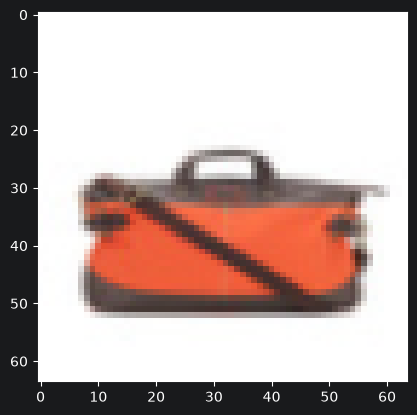

label:  [-41.819786 -24.593897   0.       -44.29441  -33.69465 ]
label.shape:  (5,)
包


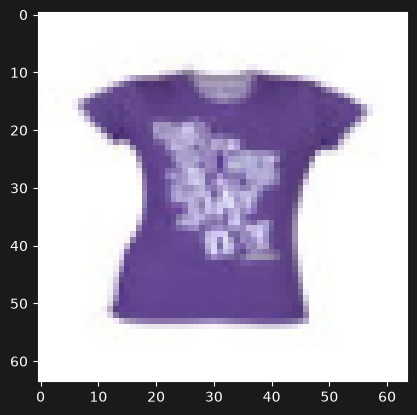

label:  [-1.1920928e-07 -3.9508305e+01 -1.6514763e+01 -2.3077259e+01
 -2.1639656e+01]
label.shape:  (5,)
上身衣服


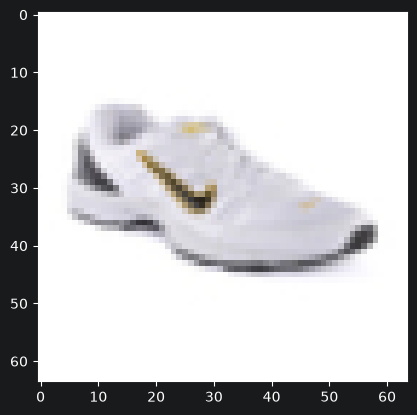

label:  [-20.521326   0.       -20.090656 -26.194662 -26.738537]
label.shape:  (5,)
鞋


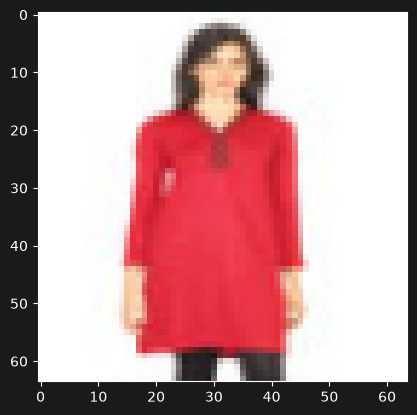

label:  [  0.       -46.945213 -24.690908 -22.179611 -30.722416]
label.shape:  (5,)
上身衣服


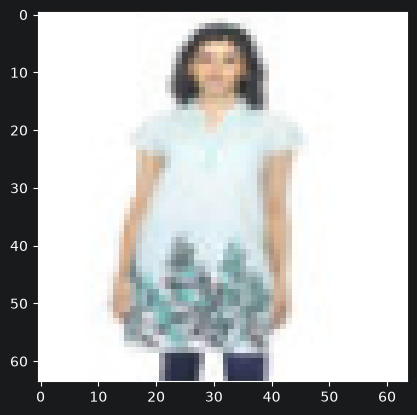

label:  [  0.       -35.384857 -26.524704 -19.024757 -39.562004]
label.shape:  (5,)
上身衣服


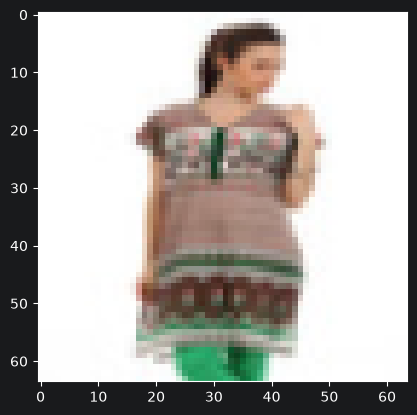

label:  [  0.       -42.731827 -30.72036  -22.716364 -24.098555]
label.shape:  (5,)
上身衣服


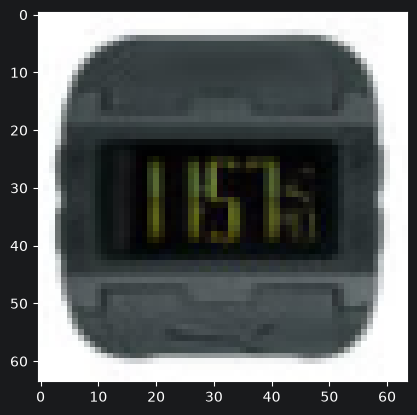

label:  [-7.6000323e+00 -3.8950394e+01 -1.4474104e+01 -1.0387682e+01
 -5.3188956e-04]
label.shape:  (5,)
手表


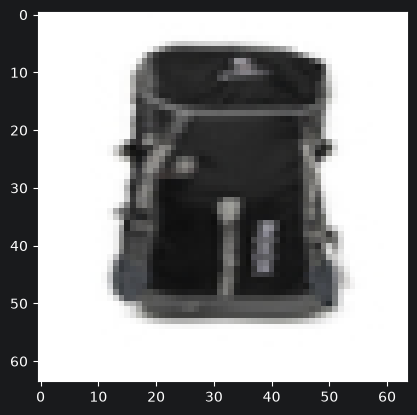

label:  [-1.4748998e+01 -3.5255226e+01 -4.0531077e-06 -1.2512491e+01
 -2.2375839e+01]
label.shape:  (5,)
包


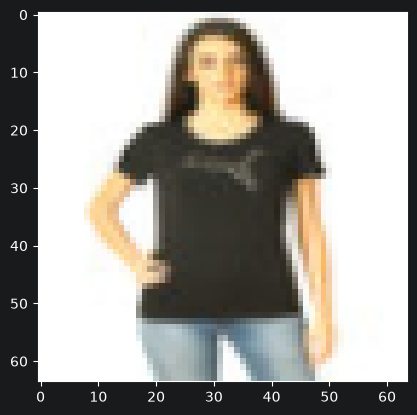

label:  [  0.       -51.84182  -37.45108  -31.0409   -55.671265]
label.shape:  (5,)
上身衣服


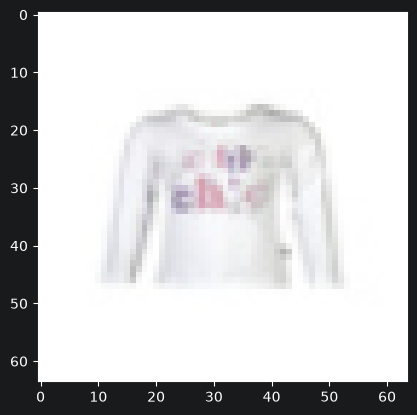

label:  [ -0.04059168 -10.86411     -6.378774    -3.2858644   -7.3320274 ]
label.shape:  (5,)
上身衣服


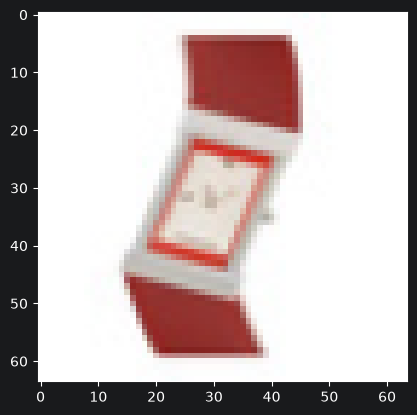

label:  [-22.586517 -59.051445 -20.440586 -24.630116   0.      ]
label.shape:  (5,)
手表


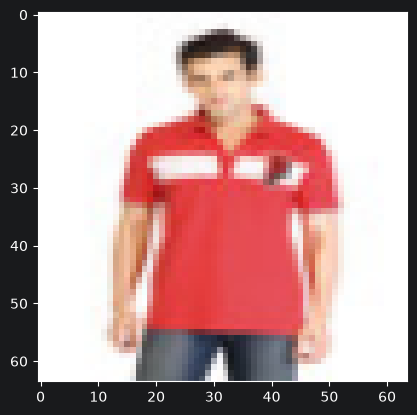

label:  [  0.       -46.74471  -34.408348 -45.54973  -47.617535]
label.shape:  (5,)
上身衣服


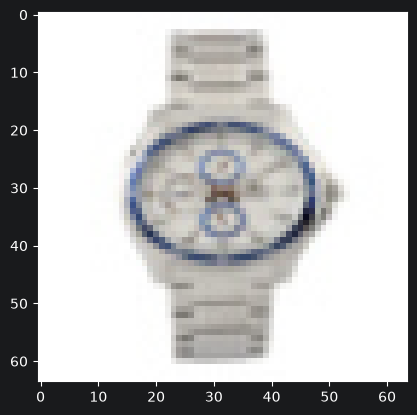

label:  [-28.481955 -41.201088 -22.638256 -19.536766   0.      ]
label.shape:  (5,)
手表


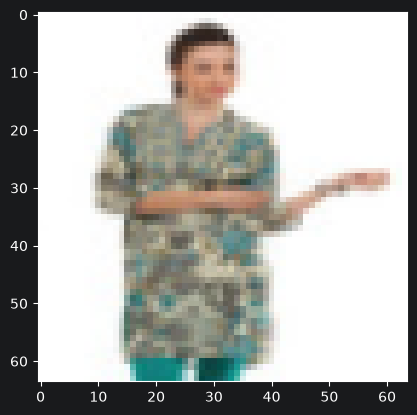

label:  [-2.8463127e-04 -1.8137705e+01 -1.0431884e+01 -8.2737675e+00
 -1.7274824e+01]
label.shape:  (5,)
上身衣服


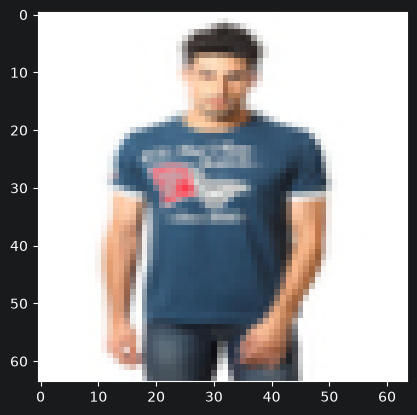

label:  [  0.       -53.69464  -40.247856 -54.30582  -50.57692 ]
label.shape:  (5,)
上身衣服


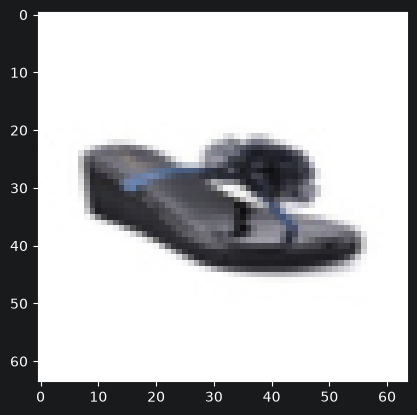

label:  [-2.9636690e+01 -1.0728830e-06 -1.3798474e+01 -1.8474272e+01
 -2.7118021e+01]
label.shape:  (5,)
鞋


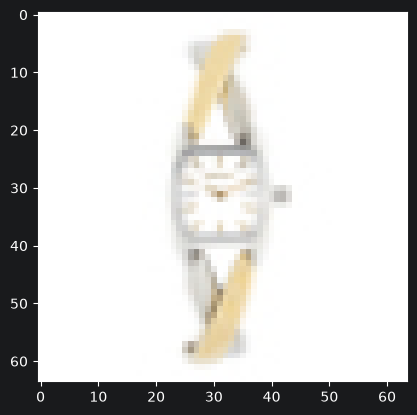

label:  [ -8.13329    -16.738256    -6.1134048   -4.1878395   -0.01784391]
label.shape:  (5,)
手表


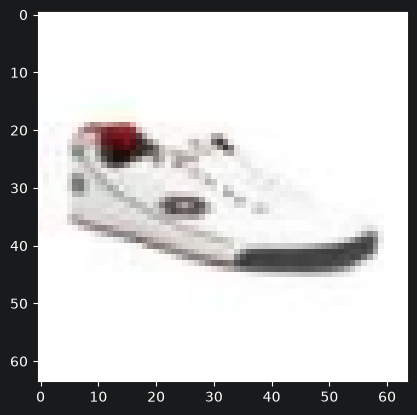

label:  [-23.46553    0.       -26.424511 -30.344757 -28.988907]
label.shape:  (5,)
鞋


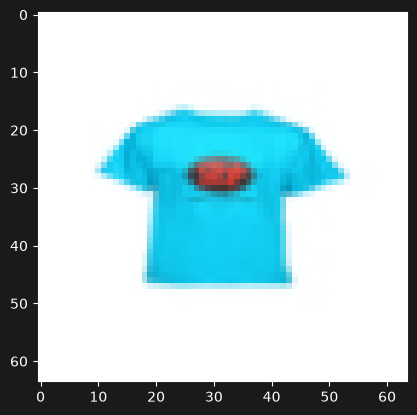

label:  [-1.1920928e-07 -2.3473183e+01 -2.0538765e+01 -1.6437000e+01
 -1.8523230e+01]
label.shape:  (5,)
上身衣服


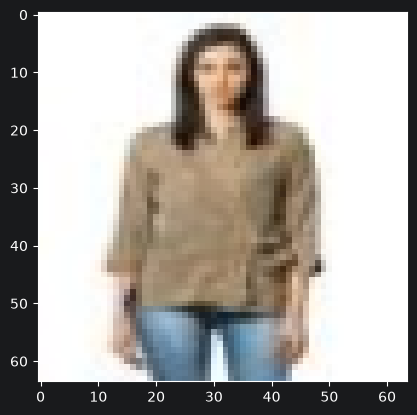

label:  [  0.       -42.62507  -22.673504 -24.126749 -40.54329 ]
label.shape:  (5,)
上身衣服


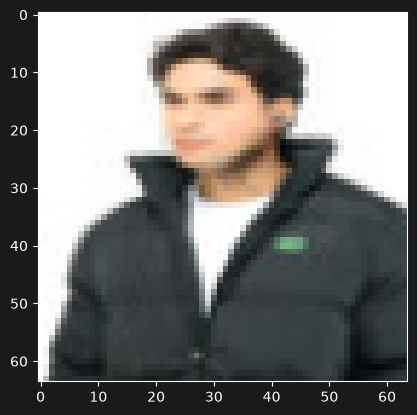

label:  [-1.4003243e-03 -3.2046894e+01 -1.1558401e+01 -6.5889621e+00
 -1.1147029e+01]
label.shape:  (5,)
上身衣服


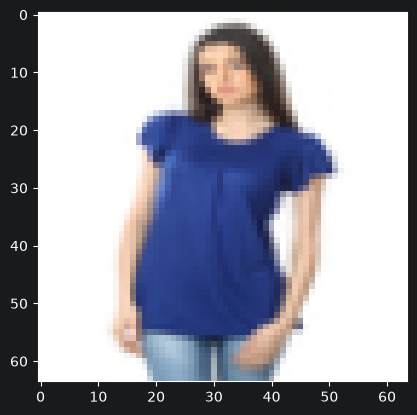

label:  [  0.       -52.239685 -25.93947  -24.912582 -38.17889 ]
label.shape:  (5,)
上身衣服


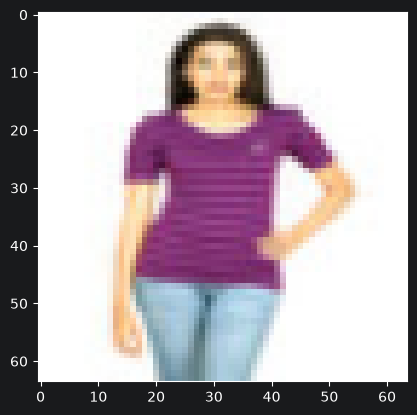

label:  [-1.1920928e-07 -3.9678658e+01 -2.3089149e+01 -1.5729088e+01
 -3.9416035e+01]
label.shape:  (5,)
上身衣服


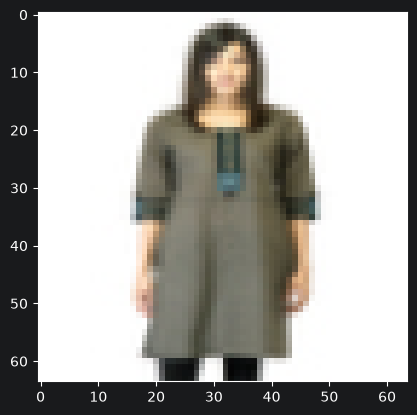

label:  [  0.       -47.96825  -30.61234  -20.339308 -31.20296 ]
label.shape:  (5,)
上身衣服


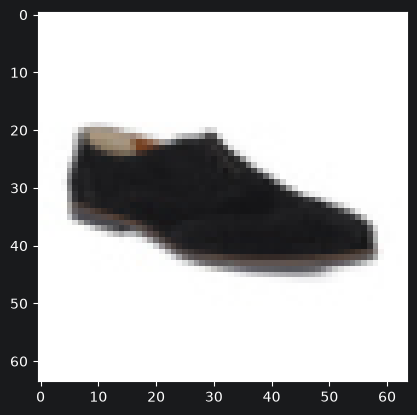

label:  [-33.624653   0.       -20.588064 -31.850267 -31.500744]
label.shape:  (5,)
鞋


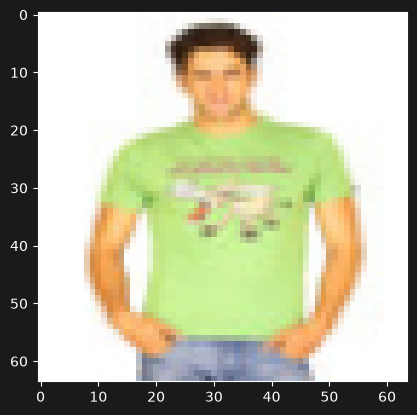

label:  [  0.       -32.311745 -24.632767 -40.46365  -32.54051 ]
label.shape:  (5,)
上身衣服


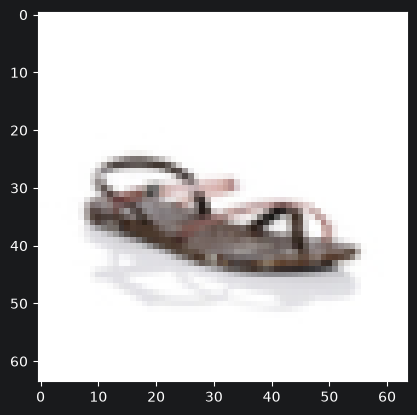

label:  [-1.90717449e+01 -1.01561156e-04 -9.19661903e+00 -1.64867992e+01
 -1.82535000e+01]
label.shape:  (5,)
鞋


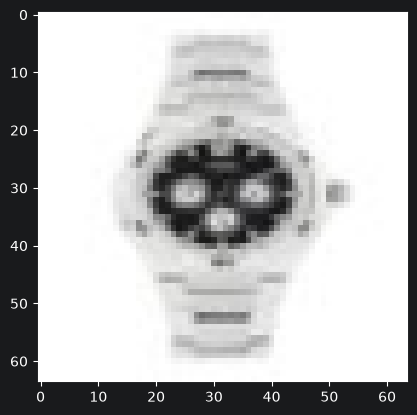

label:  [-1.7186140e+01 -2.3996878e+01 -1.3154316e+01 -1.9745466e+01
 -2.0265559e-06]
label.shape:  (5,)
手表


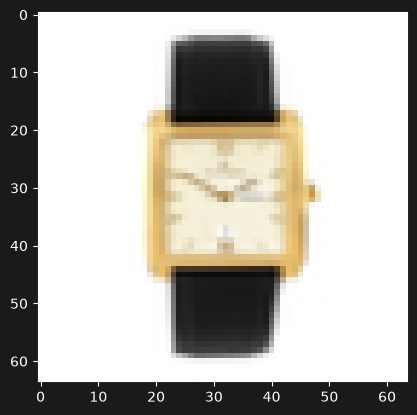

label:  [-32.82467  -68.65323  -45.22439  -28.253231   0.      ]
label.shape:  (5,)
手表


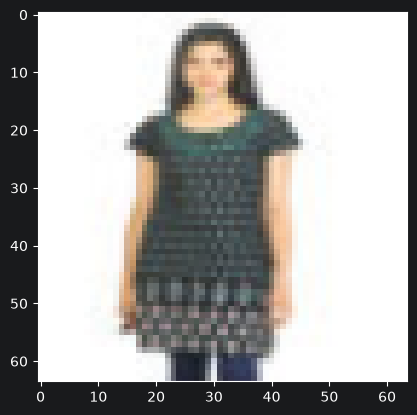

label:  [-4.7683704e-07 -3.9405846e+01 -2.1634914e+01 -1.4650644e+01
 -3.4721600e+01]
label.shape:  (5,)
上身衣服


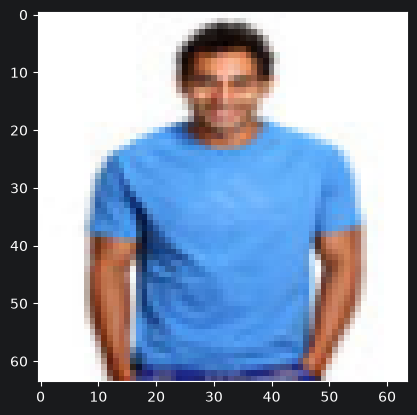

label:  [  0.       -39.263916 -30.534664 -38.309032 -43.97112 ]
label.shape:  (5,)
上身衣服


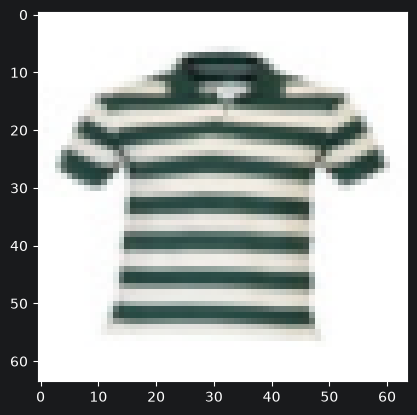

label:  [  0.       -41.862465 -29.711063 -61.727524 -35.694637]
label.shape:  (5,)
上身衣服


In [19]:
# 导入matplotlib库用于绘图
import matplotlib.pyplot as plt
# 在Jupyter Notebook中内嵌显示matplotlib图像
%matplotlib inline
# 导入numpy库用于数值计算
import numpy as np

# 获取验证集的一个批次数据
dataiter = iter(val_loader)
images, labels = next(dataiter)

# 将模型移动到CPU上，因为后续操作需要在CPU上执行
model.to('cpu')

# 获取模型对输入图像的输出结果
output = model(images)
# 将输出结果从计算图中分离，并转换为numpy数组
output = output.detach().numpy()
# 打印输出结果的形状
print(output.shape)

# 将输入图像从Tensor转换为numpy数组
images = images.numpy()
# 调整图像的维度顺序，从(C, H, W)变为(H, W, C)，以便matplotlib正确显示
images = np.moveaxis(images, 1, -1)
# 打印调整后的图像形状
print(images.shape)

# 遍历每个图像及其对应的模型输出结果
for img, label in zip(images, output):
    # 显示当前图像
    plt.imshow(img)
    plt.show()
    print("label: ", label)
    print("label.shape: ", label.shape)
    # 打印模型预测的类别名称
    print(classification_names[np.argmax(label)])
